# 5. Three renters (exploration)

A third bike rental shop opens in the street.  
This book is different from the previous ones: there are no exercises with a solution, only **small experiments**.  
The code is ready; your job is to **change the numbers, predict the result before running the cell, and explain what you see**.

> **How to work.** 
> - Before running a cell you have modified, write down (on paper, or in a comment) what you expect.  
> - The surprises are where you learn something.

## Why not use axelrod's tournaments?

An axelrod tournament with three players is in fact three separate **two-player** matches.  
That does not fit our story: a shop displays **one price for everybody**.  
It cannot keep 15 EUR for one neighbour and undercut the other.  
So we need a real three-player game.

- The file `three.py` keeps the assumptions of `bikes.py` (20 bikes per shop, prices 15 / 10 / 25 EUR, 60 % of customers still rent at 25 EUR, bad reviews) and adapts the number of customers to three shops: **30 on a quiet day, 90 on a busy day**.   
- It also contains its own season loop; we only keep axelrod's actions `C` and `D`.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from three import *

---

## 5.1 Who rents what?

`revenues(prices, customers)` gives the revenue of each shop. The rule: customers go to the cheapest shops first (split equally between shops at the same price), then to the next price level.

In [3]:
print("quiet day, all at 15 EUR      :", revenues([15, 15, 15], 30))
print("quiet day, shop 3 undercuts   :", revenues([15, 15, 10], 30))

quiet day, all at 15 EUR      : [150.0, 150.0, 150.0]
quiet day, shop 3 undercuts   : [75.0, 75.0, 200.0]


With one undercutter, shop 3 rents its 20 bikes at 10 EUR; the 10 remaining customers share the two other shops.

> **Try it** (predict first, then run):
> - two shops undercut, one keeps 15 EUR, on a quiet day;
> - on a busy day (90 customers): one shop surges to 25 EUR, the others keep 15 EUR; then two shops surge; then all three;
> - what happens to the shop that surges alone? Why?

In [3]:
print(revenues([10, 10, 15], 30))   # change the prices, and the customers (90 = busy day)

[150.0, 150.0, 0.0]


---

## 5.2 One picture per type of day: the Schelling diagram

With three shops, the game no longer fits in a 2×2 matrix.  
But the game is **symmetric**: my revenue only depends on **my move** and on **how many other shops** play D.  
The *Schelling diagram* draws exactly that: two curves, one for C, one for D.

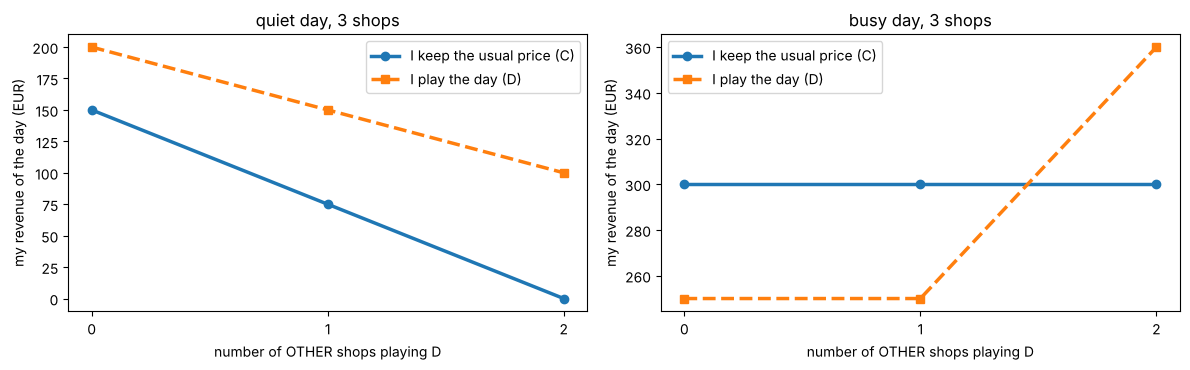

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_schelling("quiet", ax=axes[0])
plot_schelling("busy", ax=axes[1])
plt.tight_layout(); plt.show()

> **How to read it.**
> - **Quiet day**: the D curve is always above the C curve. Whatever the others do, undercutting pays more.  
Yet if everybody undercuts (right end of the D curve, 100 EUR), everybody earns less than if nobody does (left end of the C curve, 150 EUR).  
This is the **N-player prisoner's dilemma**.
> - **Busy day**: surging only pays when **both** other shops surge too.  
With the current reputation rule, one shop left at 15 EUR is enough to make every surging shop look greedy.

**Try it.** Each time, redraw the diagrams and say whether the type of game changed.
- Replace `plot_schelling("busy", ax=axes[1])` by `plot_schelling("busy", ax=axes[1], review_rule="share")`:  
the reputation cost now grows with the **share** of shops left at 15 EUR, instead of "one is enough".
- Remove the reputation cost: `bad_review=0, grumble=0`.
- Draw the diagrams for 4 shops: `n_shops=4` (think about the number of customers: is 30 still a "quiet" day for 4 shops?).
- Change the demand: `CUSTOMERS["busy"] = 60`, then put it back to 90.

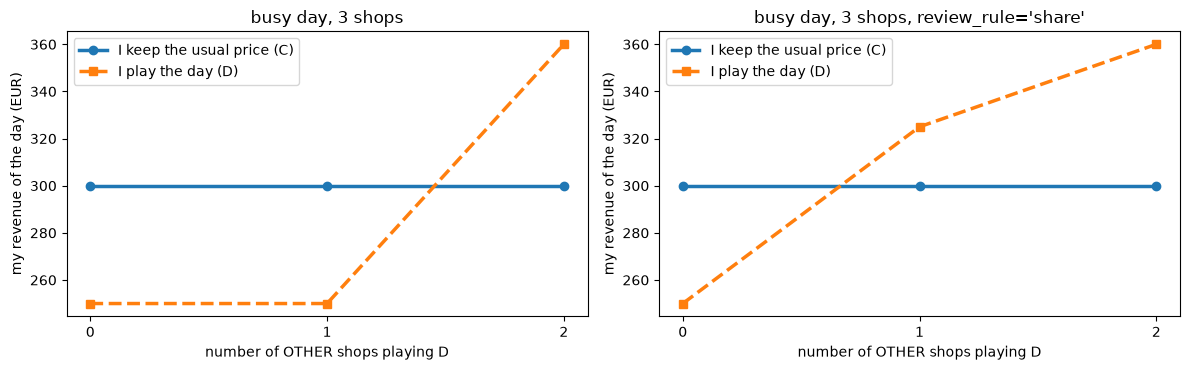

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_schelling("busy", ax=axes[0], review_rule="any")
plot_schelling("busy", ax=axes[1], review_rule="share")
axes[1].set_title("busy day, 3 shops, review_rule='share'")
plt.tight_layout(); plt.show()

--- 
## 5.3 A season with three renters

A policy is now a small function `policy(me, others, today, days)` that returns `C` or `D`:

- `me`: my past moves; `others`: the past moves of each other shop (a list of lists);
- `today`: `"quiet"` or `"busy"`; `days`: the types of the past days.

`three.py` provides `steady`, `opportunist` and `make_mirror(...)`, a Mirror for several neighbours (details in 5.4).   
`play_season(policies, calendar)` returns the revenues of each day and the moves of each shop.

In [6]:
tourist = season(TOURIST_WEEK)

policies = [steady, steady, steady]
result, history = play_season(policies, tourist)
summary(policies, result)

                  steady:  192.9 EUR per day
                  steady:  192.9 EUR per day
                  steady:  192.9 EUR per day


In [7]:
policies = [steady, steady, opportunist]
result, history = play_season(policies, tourist)
summary(policies, result)

                  steady:  139.3 EUR per day
                  steady:  139.3 EUR per day
             opportunist:  214.3 EUR per day


Now two Mirrors face one Opportunist.   
Look carefully at the moves of the first weeks:

In [8]:
policies = [make_mirror(), make_mirror(), opportunist]
result, history = play_season(policies, tourist)
show_moves(policies, history, tourist, n_days=21)
summary(policies, result)

   day (B=busy, q=quiet)  qqqqqBBqqqqqBBqqqqqBB
        mirror(q=1, b=2)  CDDDDCCDDDDDCCDDDDDCC
        mirror(q=1, b=2)  CDDDDCCDDDDDCCDDDDDCC
             opportunist  DDDDDDDDDDDDDDDDDDDDD
        mirror(q=1, b=2):  157.0 EUR per day
        mirror(q=1, b=2):  157.0 EUR per day
             opportunist:  143.4 EUR per day


> **What happens.** 
> - The two Mirrors punish the Opportunist: it now earns less than they do. 
> - But a price cut hits **every** shop in the street. When a Mirror undercuts to punish the Opportunist, the other Mirror also loses customers, and it sees a `D` coming from its fellow Mirror. 
> - Even if the Opportunist stopped undercutting, the two Mirrors would keep undercutting because of **each other**. 
> - With three players, **you cannot punish only the culprit**.

**Try it.**
- Compare the revenue of the two Mirrors here with their revenue when the street has three `steady` shops. Who pays for the punishment?
- Replace `tourist` by `season(CITY_WEEK)`. What changes, and why?
- Put three Mirrors in the street. Do they ever surge on busy days? Why not? (Hint: who would surge first?)

---

## 5.4 How sensitive should a renter be?

`make_mirror(quiet_threshold, busy_threshold)` builds a Mirror with two **thresholds**:

- on a quiet day, it undercuts if **at least `quiet_threshold`** other shops undercut on the last quiet day;
- on a busy day, it surges if **at least `busy_threshold`** other shops surged on the last busy day.

With `quiet_threshold=1`, a single undercutter triggers a reaction ("touchy" renter).  
With `quiet_threshold=2`, both neighbours must undercut ("patient" renter).

The cell below compares the two thresholds in two streets (three Mirrors, or two Mirrors and an Opportunist), with and without **mistakes** (`noise`: on 5 % of the days, a shop posts the wrong price).

In [10]:
for q in (1, 2):
    for noise in (0, 0.05):
        for street in ([make_mirror(q), make_mirror(q), make_mirror(q)],
                       [make_mirror(q), make_mirror(q), opportunist]):
            result, _ = play_season(street, tourist, noise=noise, seed=1)
            print(f"threshold {q}, noise {noise:4}:", " | ".join(f"{n} {r:5.1f}" for n, r in zip(names(street), result.mean(axis=0))))
    print()

threshold 1, noise    0: mirror(q=1, b=2) 192.9 | mirror(q=1, b=2) 192.9 | mirror(q=1, b=2) 192.9
threshold 1, noise    0: mirror(q=1, b=2) 157.0 | mirror(q=1, b=2) 157.0 | opportunist 143.4
threshold 1, noise 0.05: mirror(q=1, b=2) 156.3 | mirror(q=1, b=2) 160.3 | mirror(q=1, b=2) 155.1
threshold 1, noise 0.05: mirror(q=1, b=2) 152.1 | mirror(q=1, b=2) 156.7 | opportunist 142.3

threshold 2, noise    0: mirror(q=2, b=2) 192.9 | mirror(q=2, b=2) 192.9 | mirror(q=2, b=2) 192.9
threshold 2, noise    0: mirror(q=2, b=2) 139.3 | mirror(q=2, b=2) 139.3 | opportunist 214.3
threshold 2, noise 0.05: mirror(q=2, b=2) 189.6 | mirror(q=2, b=2) 186.7 | mirror(q=2, b=2) 190.5
threshold 2, noise 0.05: mirror(q=2, b=2) 141.2 | mirror(q=2, b=2) 139.8 | opportunist 190.4



> **Take a moment with these numbers.** Each threshold protects against one danger and leaves you exposed to the other:
> - the **touchy** Mirror (threshold 1) punishes the Opportunist, but with mistakes, three touchy Mirrors fall into price wars and lose about 35 EUR per day;
> - the **patient** Mirror (threshold 2) is hardly affected by mistakes, but a single Opportunist exploits it all season: one patient Mirror never sees **two** undercutters, since the other Mirror does not undercut.

There is no threshold that is good against everything: what matters is what you expect in your street.

**Try it.**
- Change the busy threshold: `make_mirror(1, 1)`. Do the Mirrors now coordinate on 25 EUR on busy days? Is it a good idea with `review_rule="any"`? With `review_rule="share"` (pass it to `play_season`)?
- Try the active city: `season(CITY_WEEK)`.
- Increase the noise to 0.1, or decrease it to 0.01. Where does the touchy Mirror stop being a good idea?
- Draw a bar chart of the mean revenues of one street for both thresholds.

---
## 5.5 Your own policy

Write a policy and put it in a street.  
Here is a template, a Mirror that **forgives a single mistake**: on a quiet day, it undercuts only if some other shop undercut on **both** of the last two quiet days.

In [10]:
def forgiving(me, others, today, days):
    if today == "busy":
        return C
    quiet_moves = [[m for m, d in zip(moves, days) if d == "quiet"] for moves in others]
    if any(moves[-2:] == [D, D] for moves in quiet_moves):
        return D
    return C

policies = [forgiving, make_mirror(), opportunist]
result, history = play_season(policies, tourist, noise=0.05, seed=1)
summary(policies, result)

               forgiving:  154.3 EUR per day
        mirror(q=1, b=2):  158.7 EUR per day
             opportunist:  142.6 EUR per day


> **Ideas to explore.**
> - A **leader**: a policy that surges first on busy days, hoping the others will follow. Who benefits from having a leader in the street?
> - A **coalition**: two shops that follow each other, and ignore the third one.
> - **Shops in a line** (A, B, C along a road): A and C each compete only with B. How would you change `rentals` to model it? Who is in the most difficult position?
> - **Four shops**: `play_season` and `plot_schelling` work with any number of shops; adapt `CUSTOMERS` first.
>
> For each idea: what do you **expect**, what do you **observe**, and how do you **explain** the difference?